# 01 · Reading the workbook

What the app sees when it opens your Excel file, and why it reads it the way it does.

This notebook covers `flashcards/workbook.py` and `flashcards/models.py`: which sheets
count as vocabulary, how a row becomes a `Card`, and how scores are normalised.

> Everything here runs on a generated 48-word workbook (`demo_workbook.py`), not on your
> real vocabulary — `data/` is gitignored, so these notebooks work on a fresh clone.

In [1]:
import sys
from pathlib import Path

# The notebooks live in experiments/; the flashcards package sits one level up.
ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "experiments")]

import pandas as pd
from demo_workbook import make_demo_workbook

# Rebuilt on every run, so a write-back from a previous run never leaks in.
WORKBOOK = make_demo_workbook(ROOT / "experiments" / "_demo" / "demo_vocab.xlsx")
print(WORKBOOK.relative_to(ROOT))

experiments/_demo/demo_vocab.xlsx


## 1. Which sheets count as vocabulary

A real workbook mixes word tables with formula-driven dashboards. The app must read the
first and never touch the second, and it must keep working when you add a new topic sheet
without telling it.

The rule is structural, not a hard-coded list: **column A says `German` and column L
mentions `confidence`**. Anything else is a dashboard.

In [2]:
from openpyxl import load_workbook
from flashcards.models import NON_TOPIC_SHEETS, is_topic_header
from flashcards.workbook import load_cards

raw = load_workbook(WORKBOOK, read_only=True)
data = load_cards(str(WORKBOOK))

rows = []
for name in raw.sheetnames:
    header = list(next(raw[name].iter_rows(values_only=True), []))
    rows.append({
        "sheet": name,
        "col A": header[0] if header else None,
        "col L": header[11] if len(header) > 11 else None,
        "name blocked": name in NON_TOPIC_SHEETS,
        "looks like words": is_topic_header(header),
        "read as topic": name in data.topics,
    })
raw.close()
pd.DataFrame(rows)

,sheet,col A,col L,name blocked,looks like words,read as topic
0,Overview,Topic,None,True,False,False
1,School & Office,German,Confidence (1-5),False,True,True
2,Household,German,Confidence (1-5),False,True,True
3,Travel & Transport,German,Confidence (1-5),False,True,True
4,Verbs,German,Confidence (1-5),False,True,True
5,Adjectives & Adverbs,German,Confidence (1-5),False,True,True
6,Feelings & Abstract,German,Confidence (1-5),False,True,True
7,Card Pool,Topic,None,True,False,False


`Overview` and `Card Pool` are skipped: the first fails the header test, the second is
also on the name blocklist. The six word sheets come through.

Adding a seventh topic sheet needs no code change at all.

In [3]:
print(f"{len(data.cards)} words across {len(data.topics)} topics")
print(data.topics)

48 words across 6 topics
['School & Office', 'Household', 'Travel & Transport', 'Verbs', 'Adjectives & Adverbs', 'Feelings & Abstract']


## 2. Columns are read by position, not by label

This is the subtlety that shapes `models.py`. The topic sheets do **not** share header
text. Column D is `Article` on a noun sheet, `Article / Auxiliary` on the verb sheet and
`Article (n/a)` on the adjective sheet; column E varies the same way.

Matching on labels would silently drop the verb auxiliaries. So the app matches on
*position* (A..L) and keeps the real labels only to caption the UI.

In [4]:
raw = load_workbook(WORKBOOK, read_only=True)
labels = pd.DataFrame(
    [{"sheet": t, "column D": list(next(raw[t].iter_rows(values_only=True)))[3],
      "column E": list(next(raw[t].iter_rows(values_only=True)))[4]} for t in data.topics]
)
raw.close()
labels

,sheet,column D,column E
0,School & Office,Article,Plural
1,Household,Article,Plural
2,Travel & Transport,Article,Plural
3,Verbs,Article / Auxiliary,Plural / Verb forms
4,Adjectives & Adverbs,Article (n/a),Comparative / Superlative
5,Feelings & Abstract,Article,Plural


In [5]:
# Same position, different meaning -- and every one of them parsed correctly.
by_word = {c.german: c for c in data.cards}
pd.DataFrame([
    {"word": w, "sheet": by_word[w].sheet, "D label": by_word[w].article_label,
     "D value": by_word[w].article_aux, "E label": by_word[w].forms_label,
     "E value": by_word[w].forms}
    for w in ("Stift", "werden", "riesig")
])

,word,sheet,D label,D value,E label,E value
0,Stift,School & Office,Article,der,Plural,die Stifte
1,werden,Verbs,Article / Auxiliary,sein,Plural / Verb forms,wird - wurde - ist geworden
2,riesig,Adjectives & Adverbs,Article (n/a),-,Comparative / Superlative,riesiger - am riesigsten


## 3. One card, in full

A `Card` carries the vocabulary fields *and* its physical address in the workbook
(`sheet` + `row`). That address is what the write-back later edits. It is captured at
parse time rather than derived from list position, because filtering the deck would
otherwise shift every row number.

In [6]:
card = by_word["werden"]
pd.Series({
    "id (session key)": card.id,
    "sheet / row (write-back address)": f"{card.sheet}!row {card.row}",
    "german": card.german, "english": card.english, "word_type": card.word_type,
    f"{card.article_label}": card.article_aux,
    f"{card.forms_label}": card.forms,
    "example (de)": card.example_de, "example (en)": card.example_en,
    "date_added": card.date_added, "confidence": card.confidence,
}).to_frame("value")

,value
id (session key),Verbs!2
sheet / row (write-back address),Verbs!row 2
german,werden
english,to become
word_type,Verb
Article / Auxiliary,sein
Plural / Verb forms,wird - wurde - ist geworden
example (de),Sie will Aerztin werden.
example (en),She wants to become a doctor.
date_added,2026-07-11


## 4. Scores are normalised on the way in

`coerce_confidence` is deliberately forgiving about what a cell contains. A blank means
*ungraded*, which is different from a low score: an ungraded word has never been tested,
so it is excluded from "difficult words only" but ranks top of the weighted draw.

Out-of-range values are clamped rather than dropped — a stray `0` or `7` typed by hand
should still become a usable grade instead of silently vanishing. Values are snapped onto
the half-step grid, because grading averages produce halves (notebook 03).

In [7]:
from flashcards.models import coerce_confidence

pd.DataFrame(
    [{"cell contains": repr(v), "parsed as": coerce_confidence(v)}
     for v in [None, "", "  ", 3, 3.0, "4", 3.5, "2.5", 2.8, 1.6, 0, 7, "nope"]]
)

,cell contains,parsed as
0,None,NaN
1,'',NaN
2,' ',NaN
3,3,3.0
4,3.0,3.0
5,'4',4.0
6,3.5,3.5
7,'2.5',2.5
8,2.8,3.0
9,1.6,1.5


## 5. What the app knows about your library

`WorkbookData.stats()` is what fills the "Topic overview" table in the sidebar. The
`difficult` column counts words at or below the threshold you pick — note that ungraded
words are *not* counted as difficult.

In [8]:
stats = pd.DataFrame([vars(s) for s in data.stats(difficult_threshold=2)])
stats["avg_confidence"] = stats["avg_confidence"].round(2)
stats.rename(columns={"difficult": "difficult (<=2)"})

,topic,count,graded,avg_confidence,difficult (<=2)
0,School & Office,8,6,2.17,4
1,Household,8,7,2.71,3
2,Travel & Transport,8,7,2.14,5
3,Verbs,8,8,3.88,1
4,Adjectives & Adverbs,8,7,3.00,2
5,Feelings & Abstract,8,8,3.62,2


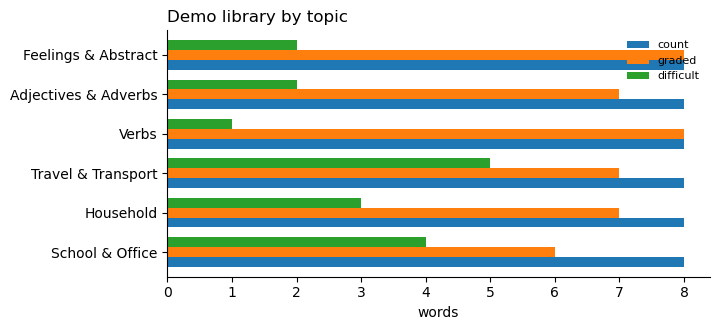

In [9]:
ax = stats.set_index("topic")[["count", "graded", "difficult"]].plot.barh(
    figsize=(7, 3.2), width=0.75)
ax.set_xlabel("words"); ax.set_ylabel("")
ax.set_title("Demo library by topic", loc="left")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

### Reading is strictly read-only

`load_cards` opens the file with openpyxl in `read_only` mode and closes it again. It also
records the file's modification time, which the write-back re-checks before touching
anything — if you edited the workbook in Excel meanwhile, the save is refused rather than
overwriting your edit.

**Next:** [02 · Choosing what to study](02_choosing_what_to_study.ipynb) — how a session's
deck is drawn from these 48 words.

In [10]:
import datetime as dt
print("loaded from :", Path(data.path).name)
print("mtime guard :", dt.datetime.fromtimestamp(data.mtime).strftime("%Y-%m-%d %H:%M:%S"))

loaded from : demo_vocab.xlsx
mtime guard : 2026-09-17 01:49:51
